In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical, Normal
import matplotlib.pyplot as plt

np.random.seed(0)
torch.manual_seed(0)

In [2]:
N_FLOORS = 6
ARRIVAL_RATE = 0.08          # passengers per second per floor
EPISODE_TIME = 300           # simulated seconds per episode
FLOOR_TIME = 2.0             # seconds to travel one floor at speed 1
SPEED_RANGE = (0.5, 2.0)
DWELL_MAX = 3.0              # max extra door-open time (s)
ENERGY_COST = 0.5
REWARD_SCALE = 10

GAMMA = 0.95
ENTROPY_COEF = 0.01
EPISODES = 2000
STATE_DIM = 1 + 2 * N_FLOORS

In [3]:
class ElevatorEnv:
    def reset(self):
        self.floor = 0
        self.time = 0.0
        self.count = np.zeros(N_FLOORS)   # passengers waiting per floor
        self.wait = np.zeros(N_FLOORS)    # total waiting time per floor
        self.served = 0.0
        self.served_wait = 0.0
        return self._state()

    def _state(self):
        avg = self.wait / np.maximum(self.count, 1)
        pos = self.floor / (N_FLOORS - 1)
        return np.concatenate([[pos], self.count / 5, avg / 30]).astype(np.float32)

    def _tick(self, dt):
        # time passes: waiting grows and new passengers arrive
        cost = self.count.sum() * dt
        self.wait += self.count * dt
        new = np.random.poisson(ARRIVAL_RATE * dt, N_FLOORS)
        self.count += new
        self.wait += new * dt / 2
        cost += new.sum() * dt / 2
        self.time += dt
        return cost

    def _board(self):
        self.served += self.count[self.floor]
        self.served_wait += self.wait[self.floor]
        self.count[self.floor] = 0
        self.wait[self.floor] = 0

    def avg_wait(self):
        total = self.served_wait + self.wait.sum()
        people = self.served + self.count.sum()
        return total / max(people, 1)

    def step(self, direction, speed, dwell):
        move = 1 if direction == 1 else -1
        self.floor = int(np.clip(self.floor + move, 0, N_FLOORS - 1))
        cost = self._tick(FLOOR_TIME / speed)   # travel to next floor
        self._board()
        cost += self._tick(dwell)               # doors stay open
        self._board()
        reward = -(cost + ENERGY_COST * speed ** 2) / REWARD_SCALE
        done = self.time >= EPISODE_TIME
        return self._state(), reward, done

In [4]:
class Actor(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(STATE_DIM, 64), nn.Tanh(),
                                  nn.Linear(64, 64), nn.Tanh())
        self.direction = nn.Linear(64, 2)                # up / down
        self.mean = nn.Linear(64, 2)                     # speed, dwell
        self.log_std = nn.Parameter(torch.full((2,), -0.5))

    def forward(self, s):
        h = self.body(s)
        return Categorical(logits=self.direction(h)), Normal(self.mean(h), self.log_std.exp())


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(STATE_DIM, 64), nn.Tanh(),
                                 nn.Linear(64, 64), nn.Tanh(),
                                 nn.Linear(64, 1))

    def forward(self, s):
        return self.net(s)


actor, critic = Actor(), Critic()
actor_opt = torch.optim.Adam(actor.parameters(), lr=1e-3)
critic_opt = torch.optim.Adam(critic.parameters(), lr=3e-3)

In [5]:
def to_env_action(raw):
    low, high = SPEED_RANGE
    speed = low + (high - low) * torch.sigmoid(raw[..., 0])
    dwell = DWELL_MAX * torch.sigmoid(raw[..., 1])
    return speed, dwell

In [6]:
def run_episode(env, actor):
    s, done = env.reset(), False
    S, D, Raw, R, S2, Dn = [], [], [], [], [], []
    while not done:
        with torch.no_grad():
            d_dist, c_dist = actor(torch.tensor(s))
            d, raw = d_dist.sample(), c_dist.sample()
        speed, dwell = to_env_action(raw)
        s2, r, done = env.step(d.item(), speed.item(), dwell.item())
        S.append(s); D.append(d); Raw.append(raw)
        R.append(r); S2.append(s2); Dn.append(float(done))
        s = s2
    batch = (torch.tensor(np.array(S)), torch.stack(D), torch.stack(Raw),
             torch.tensor(R, dtype=torch.float32),
             torch.tensor(np.array(S2)), torch.tensor(Dn))
    return batch, sum(R)

In [7]:
def update(batch):
    S, D, Raw, R, S2, Dn = batch

    value = critic(S).squeeze(-1)
    with torch.no_grad():
        target = R + GAMMA * critic(S2).squeeze(-1) * (1 - Dn)
    critic_loss = F.mse_loss(value, target)

    advantage = (target - value).detach()
    advantage = (advantage - advantage.mean()) / (advantage.std() + 1e-8)

    d_dist, c_dist = actor(S)
    log_prob = d_dist.log_prob(D) + c_dist.log_prob(Raw).sum(-1)
    entropy = d_dist.entropy() + c_dist.entropy().sum(-1)
    actor_loss = -(log_prob * advantage).mean() - ENTROPY_COEF * entropy.mean()

    critic_opt.zero_grad()
    critic_loss.backward()
    critic_opt.step()

    actor_opt.zero_grad()
    actor_loss.backward()
    nn.utils.clip_grad_norm_(actor.parameters(), 1.0)
    actor_opt.step()

In [8]:
env = ElevatorEnv()
return_log, wait_log = [], []

for ep in range(EPISODES):
    batch, ep_return = run_episode(env, actor)
    update(batch)
    return_log.append(ep_return)
    wait_log.append(env.avg_wait())
    if (ep + 1) % 200 == 0:
        print(f"Episode {ep + 1}: return {np.mean(return_log[-200:]):.1f}, "
              f"avg wait {np.mean(wait_log[-200:]):.1f}s")

Episode 200: return -1162.5, avg wait 77.7s
Episode 400: return -1632.2, avg wait 108.5s
Episode 600: return -594.2, avg wait 37.6s
Episode 800: return -153.0, avg wait 6.7s
Episode 1000: return -138.2, avg wait 5.8s
Episode 1200: return -126.5, avg wait 4.7s
Episode 1400: return -123.0, avg wait 4.4s
Episode 1600: return -116.5, avg wait 3.9s
Episode 1800: return -116.5, avg wait 3.9s
Episode 2000: return -113.1, avg wait 3.7s


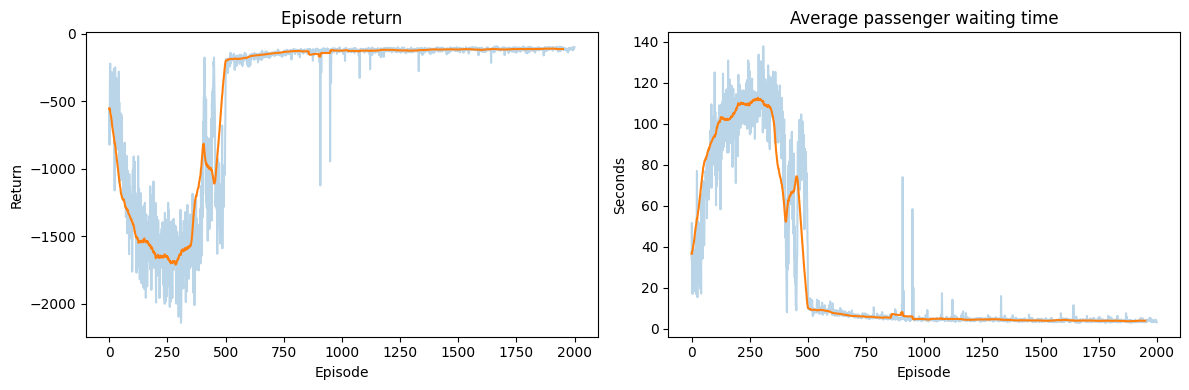

In [9]:
def smooth(x, k=50):
    return np.convolve(x, np.ones(k) / k, mode="valid")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(return_log, alpha=0.3)
ax[0].plot(smooth(return_log))
ax[0].set(title="Episode return", xlabel="Episode", ylabel="Return")

ax[1].plot(wait_log, alpha=0.3)
ax[1].plot(smooth(wait_log))
ax[1].set(title="Average passenger waiting time", xlabel="Episode", ylabel="Seconds")
plt.tight_layout()
plt.show()

Random : 32.3 ± 8.5 s
Trained: 3.6 ± 0.5 s


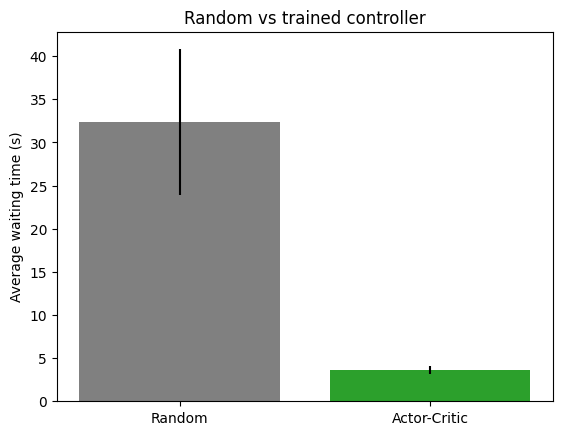

In [10]:
def random_policy(s):
    return np.random.randint(2), np.random.uniform(*SPEED_RANGE), np.random.uniform(0, DWELL_MAX)

def trained_policy(s):
    with torch.no_grad():
        d_dist, c_dist = actor(torch.tensor(s))
        speed, dwell = to_env_action(c_dist.mean)
    return d_dist.probs.argmax().item(), speed.item(), dwell.item()

def evaluate(policy, episodes=30):
    waits = []
    for _ in range(episodes):
        s, done = env.reset(), False
        while not done:
            s, _, done = env.step(*policy(s))
        waits.append(env.avg_wait())
    return np.mean(waits), np.std(waits)

rand_mean, rand_std = evaluate(random_policy)
agent_mean, agent_std = evaluate(trained_policy)
print(f"Random : {rand_mean:.1f} ± {rand_std:.1f} s")
print(f"Trained: {agent_mean:.1f} ± {agent_std:.1f} s")

plt.bar(["Random", "Actor-Critic"], [rand_mean, agent_mean],
        yerr=[rand_std, agent_std], color=["gray", "tab:green"])
plt.ylabel("Average waiting time (s)")
plt.title("Random vs trained controller")
plt.show()

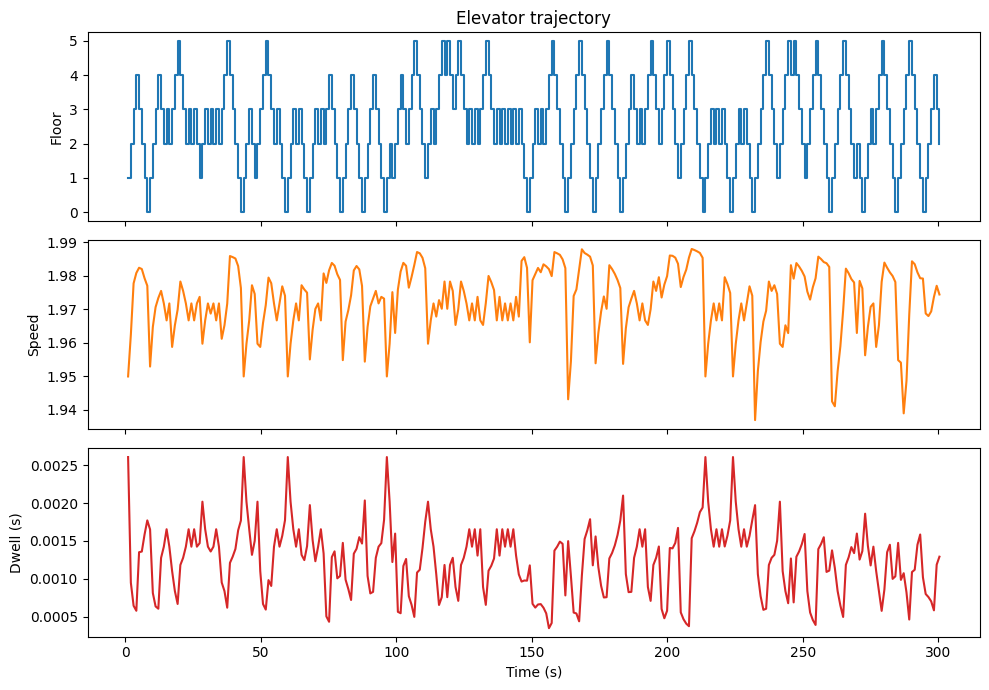

In [11]:
s, done = env.reset(), False
times, floors, speeds, dwells = [], [], [], []
while not done:
    d, speed, dwell = trained_policy(s)
    s, _, done = env.step(d, speed, dwell)
    times.append(env.time); floors.append(env.floor)
    speeds.append(speed); dwells.append(dwell)

fig, ax = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
ax[0].step(times, floors, where="post")
ax[0].set(ylabel="Floor", title="Elevator trajectory")
ax[1].plot(times, speeds, color="tab:orange")
ax[1].set(ylabel="Speed")
ax[2].plot(times, dwells, color="tab:red")
ax[2].set(ylabel="Dwell (s)", xlabel="Time (s)")
plt.tight_layout()
plt.show()